In [1]:
print("Saeed")

Saeed


In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt 

In [2]:
weight = 0.9
bias = 0.1 

start = 0
stop = 1
step = 0.005

X = torch.arange(start , stop , step).unsqueeze(dim=1)
y = weight * X + bias

In [5]:
X[:5] , y[:5] , len(X) , len(y)

(tensor([[0.0000],
         [0.0050],
         [0.0100],
         [0.0150],
         [0.0200]]),
 tensor([[0.1000],
         [0.1045],
         [0.1090],
         [0.1135],
         [0.1180]]),
 200,
 200)

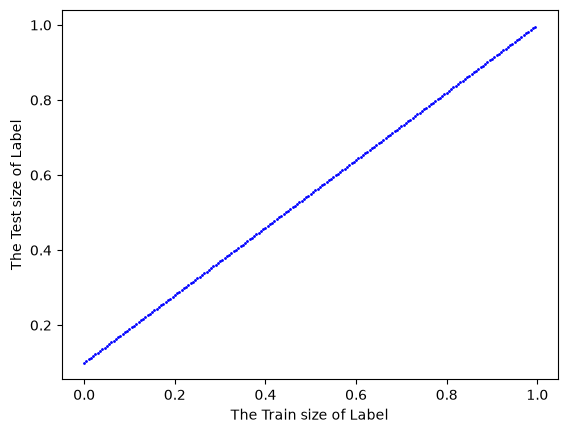

In [6]:
plt.scatter(X , y , c='b' , s=1)
plt.xlabel("The Train size of Label")
plt.ylabel("The Test size of Label")
plt.show()

In [8]:
len(X) , len(y)

(200, 200)

In [7]:
train_splt = int(len(X) * 0.85)
X_train , y_train = X[:train_splt] , y[:train_splt]
X_test , y_test = X[train_splt:] , y[train_splt:]

In [9]:
print(f"The Size of X_Train {len(X_train)}")
print(f"The Size of Y_Train {len(y_train)}")
print(f"The Size of X_test {len(X_test)}")
print(f"The Size of Y_Test {len(y_test)}")

The Size of X_Train 170
The Size of Y_Train 170
The Size of X_test 30
The Size of Y_Test 30


In [26]:
def plot_the_graph(X_train = X_train,
                   y_train = y_train,
                   X_test_data = X_test,
                   y_test_data = y_test,
                   predictions = None):
    plt.figure(figsize=(10,7))
    #The Plotting of the graph
    plt.scatter(X_train , y_train , c="b" , s=1 , label="Training Data")
    plt.scatter(X_test_data , y_test_data , c='g' , s=1 , label="Testing Data")

    #The Plotting of the 
    if predictions is not None:
        plt.scatter(X_test_data , predictions , c='r' , s=1 , label="Predictions")
    plt.legend() 
    plt.show()
       
    

In [11]:
class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(1 , requires_grad=True))
        self.bias = nn.Parameter(torch.randn(1 , requires_grad=True))
    def forward(self , X):
        return self.weights * X + self.bias
    

In [12]:
torch.manual_seed(42)
model = LinearRegression()

In [34]:
list(model.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [25]:
with torch.no_grad(): #No gradient tracking is required for this operation
   print(f"Prediction before training")
   y_pred = model(X_test) #It will give y predict based on Random Weight and Bias selected by the torch

Prediction before training


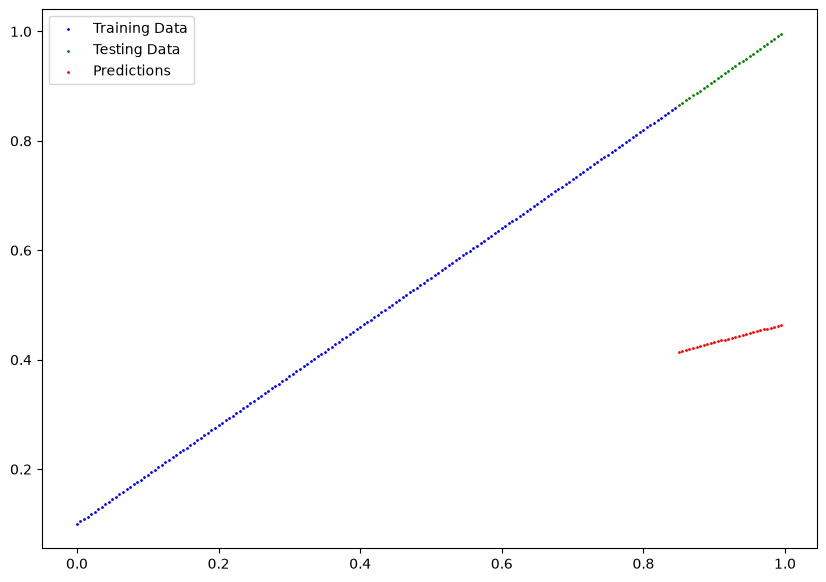

In [27]:
plot_the_graph(predictions=y_pred)

In [28]:
loss_fun = nn.L1Loss()
#Training loss Now we will Calculate loss = lossfunction(y_predict , y_train)

In [30]:
y_predict_loss = model(X_train)

In [31]:
loss = loss_fun(y_predict_loss , y_train)

In [32]:
loss

tensor(0.2111, grad_fn=<MeanBackward0>)

In [33]:
optimzer = torch.optim.SGD(
    params=model.parameters(),
    lr=0.01
)


In [39]:
epochs = 500
for epoch in range(epochs):
    
    #Now training the Model
    model.train()
    
    #Traning Prediction
    y_predict = model(X_train)
    
    #Training Loss
    loss = loss_fun(y_predict , y_train)
    
    #Remove Past Gradient from optimizer
    optimzer.zero_grad()
    
    #BackPropogation
    loss.backward()
    
    #Update Parameters
    optimzer.step()
    
    print(f"Epoch : {epoch} | Loss : {loss.item()}")

Epoch : 0 | Loss : 0.030252007767558098
Epoch : 1 | Loss : 0.029873497784137726
Epoch : 2 | Loss : 0.029494989663362503
Epoch : 3 | Loss : 0.02911648154258728
Epoch : 4 | Loss : 0.02873818390071392
Epoch : 5 | Loss : 0.02835971675813198
Epoch : 6 | Loss : 0.02798120304942131
Epoch : 7 | Loss : 0.027602704241871834
Epoch : 8 | Loss : 0.027224186807870865
Epoch : 9 | Loss : 0.02684568241238594
Epoch : 10 | Loss : 0.026467224583029747
Epoch : 11 | Loss : 0.026088915765285492
Epoch : 12 | Loss : 0.02571040950715542
Epoch : 13 | Loss : 0.025331897661089897
Epoch : 14 | Loss : 0.024953387677669525
Epoch : 15 | Loss : 0.024574879556894302
Epoch : 16 | Loss : 0.02419637143611908
Epoch : 17 | Loss : 0.02381802536547184
Epoch : 18 | Loss : 0.02343960851430893
Epoch : 19 | Loss : 0.02306109294295311
Epoch : 20 | Loss : 0.022682590410113335
Epoch : 21 | Loss : 0.022304072976112366
Epoch : 22 | Loss : 0.02192557230591774
Epoch : 23 | Loss : 0.021547067910432816
Epoch : 24 | Loss : 0.021168807521462

In [40]:
list(model.parameters())

[Parameter containing:
 tensor([0.8952], requires_grad=True),
 Parameter containing:
 tensor([0.0935], requires_grad=True)]

In [ ]:
model.eval()
print("Model After Training")
with torch.inference_mode():
    
    y_predicts_test = model(X_test)
    loss = loss_fun(y_predicts_test , y_test)

print(f"Loss | {loss.item()}")
    

Loss | 0.010939997620880604


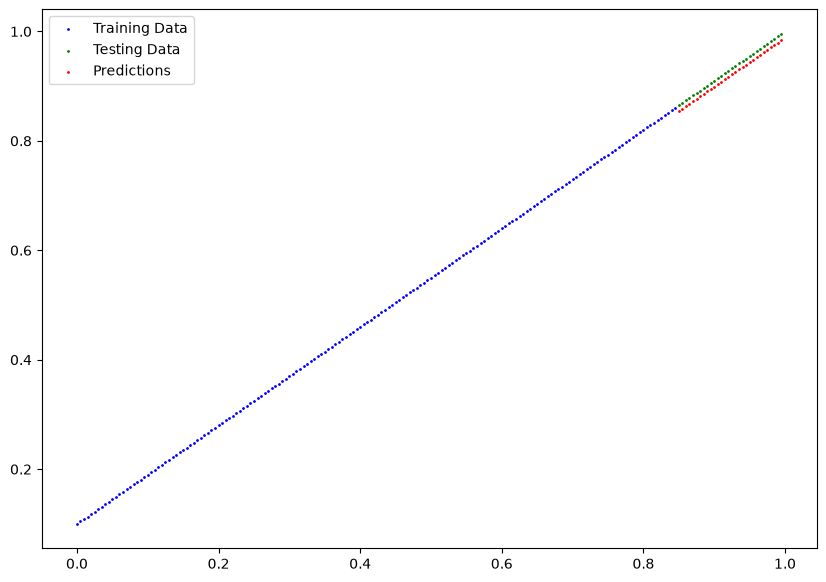

In [42]:
plot_the_graph(predictions=y_predicts_test)

In [44]:
print("\nModel Specs")
print("Model Weight" , model.weights.item())
print("Model Bias" , model.bias.item())
print("Loss" , loss.item())


Model Specs
Model Weight 0.8951699137687683
Model Bias 0.09351576864719391
Loss 0.010939997620880604
